In [2]:
# Cell 1 — imports
from pathlib import Path

import numpy as np
from PIL import Image
from scipy import ndimage
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import matplotlib.pyplot as plt

DATA_RAW = Path("../data/raw/Badulla")
DATA_PROCESSED = Path("../data/processed")
DATA_RAW.mkdir(parents=True, exist_ok=True)

In [3]:
import fitz
from pathlib import Path

def pdf_to_png(pdf_path, out_prefix, dpi=300):
    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    doc = fitz.open(pdf_path)

    page = doc[0]

    zoom = dpi / 72
    matrix = fitz.Matrix(zoom, zoom)

    pix = page.get_pixmap(matrix=matrix, alpha=False)

    png_path = Path(f"{out_prefix}-1.png")
    pix.save(str(png_path))

    doc.close()

    return png_path

In [4]:
MAP_NAME = "Badulla" 

In [5]:
pdf_path = DATA_RAW / f"{MAP_NAME.upper()}.pdf"

png_path = pdf_to_png(
    pdf_path,
    str(DATA_RAW / MAP_NAME)
)

im = Image.open(png_path).convert("RGB")
arr = np.array(im)

In [6]:
def find_frame_borders_badulla(arr):
    h, w, _ = arr.shape

    # =========================================================
    # LEFT BORDER
    # Badulla map begins close to the left edge
    # =========================================================
    x0, x1 = int(w * 0.02), int(w * 0.08)

    region = arr[
        int(h * 0.15):int(h * 0.85),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Badulla left map border."
        )

    left = candidates[0] + x0


    # =========================================================
    # RIGHT BORDER
    # Map ends immediately before legend/table area
    # =========================================================
    x0, x1 = int(w * 0.60), int(w * 0.68)

    region = arr[
        int(h * 0.15):int(h * 0.85),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Badulla right map border."
        )

    right = candidates[0] + x0


    # =========================================================
    # TOP BORDER
    # Below red title/header
    # =========================================================
    y0, y1 = int(h * 0.06), int(h * 0.13)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Badulla top map border."
        )

    top = candidates[0] + y0


    # =========================================================
    # BOTTOM BORDER
    # Above red footer
    # =========================================================
    y0, y1 = int(h * 0.88), int(h * 0.96)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Badulla bottom map border."
        )

    bottom = candidates[-1] + y0

    return left, right, top, bottom


# ============================================================
# RUN BADULLA FRAME DETECTION
# ============================================================

X_MIN, X_MAX, Y_MIN, Y_MAX = (
    find_frame_borders_badulla(arr)
)

print(
    f"Badulla frame: "
    f"x=[{X_MIN}, {X_MAX}], "
    f"y=[{Y_MIN}, {Y_MAX}]"
)

print(
    "Frame width:",
    X_MAX - X_MIN
)

print(
    "Frame height:",
    Y_MAX - Y_MIN
)

Badulla frame: x=[170, 3191], y=[277, 3366]
Frame width: 3021
Frame height: 3089


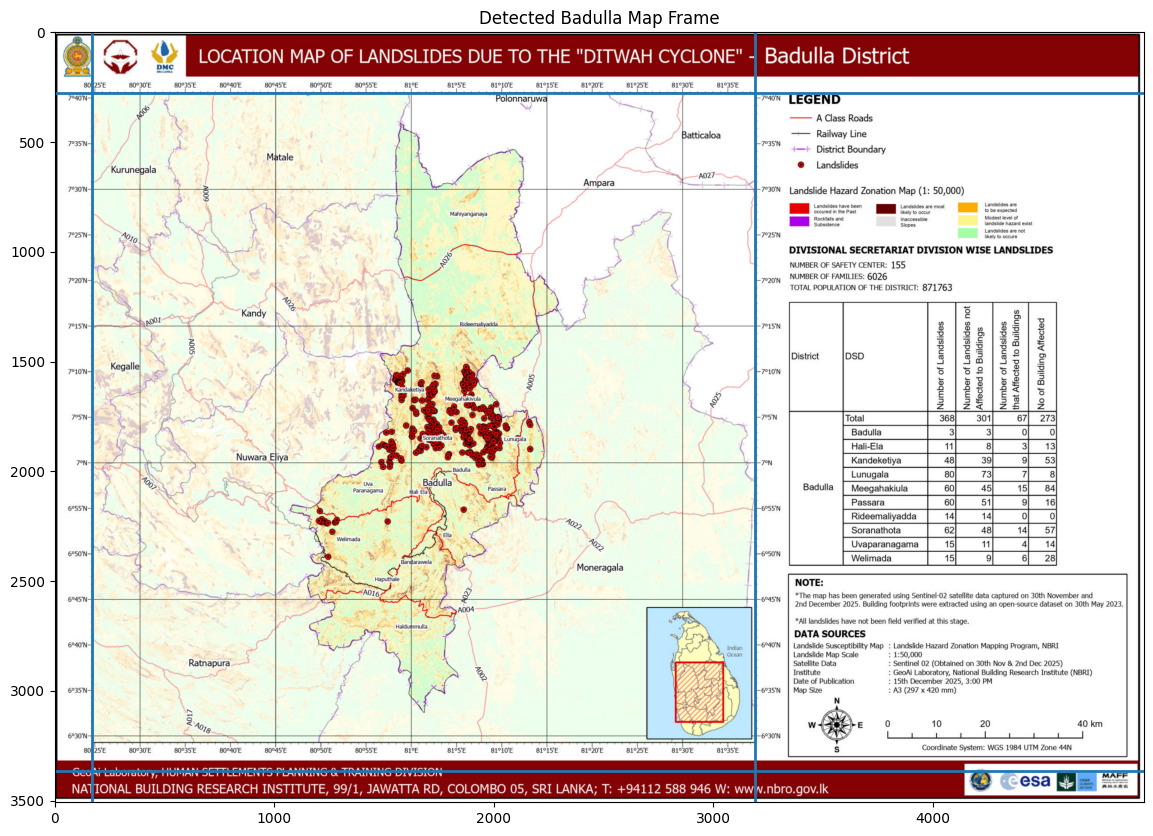

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

plt.imshow(arr)

plt.axvline(X_MIN, linewidth=2)
plt.axvline(X_MAX, linewidth=2)

plt.axhline(Y_MIN, linewidth=2)
plt.axhline(Y_MAX, linewidth=2)

plt.xlim(0, arr.shape[1])
plt.ylim(arr.shape[0], 0)

plt.title("Detected Badulla Map Frame")
plt.show()

In [8]:
def zoom_crop(arr, x0, y0, x1, y1, scale=3, save_path="zoom_check.png"):
    crop = Image.fromarray(arr[y0:y1, x0:x1])
    crop = crop.resize(
        (crop.width * scale, crop.height * scale),
        Image.LANCZOS
    )
    crop.save(save_path)
    return save_path

In [9]:
# ============================================================
# Badulla — Find Exact Graticule/Gridline Pixel Positions
# ============================================================

def find_vertical_gridline_badulla(
    arr,
    x_search_start,
    x_search_end,
    y0,
    y1,
    dark_threshold=400,
    min_fraction=0.40
):
    """
    Find the exact X pixel position of a vertical longitude
    gridline inside a narrow search window.

    x_search_start and x_search_end should surround ONE
    expected longitude gridline only.
    """

    # Keep search inside detected Badulla map frame
    x_search_start = max(x_search_start, X_MIN)
    x_search_end   = min(x_search_end, X_MAX)

    y0 = max(y0, Y_MIN)
    y1 = min(y1, Y_MAX)

    strip = arr[
        y0:y1,
        x_search_start:x_search_end,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each X position
    frac_dark = (
        gray < dark_threshold
    ).mean(axis=0)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Strongest vertical dark response
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(
        strongest + x_search_start
    )


def find_horizontal_gridline_badulla(
    arr,
    y_search_start,
    y_search_end,
    x0,
    x1,
    dark_threshold=400,
    min_fraction=0.40
):
    """
    Find the exact Y pixel position of a horizontal latitude
    gridline inside a narrow search window.

    y_search_start and y_search_end should surround ONE
    expected latitude gridline only.
    """

    # Keep search inside detected Badulla map frame
    y_search_start = max(
        y_search_start,
        Y_MIN
    )

    y_search_end = min(
        y_search_end,
        Y_MAX
    )

    x0 = max(x0, X_MIN)
    x1 = min(x1, X_MAX)

    strip = arr[
        y_search_start:y_search_end,
        x0:x1,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each Y position
    frac_dark = (
        gray < dark_threshold
    ).mean(axis=1)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Strongest horizontal dark response
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(
        strongest + y_search_start
    )

In [10]:
# ============================================================
# BADULLA — IDENTIFY GRATICULE PIXEL POSITIONS
# Uses X_MIN, X_MAX, Y_MIN, Y_MAX obtained from
# find_frame_borders_badulla(arr)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks


# ------------------------------------------------------------
# Avoid the outer black map frame
# ------------------------------------------------------------

margin = 30

x0 = X_MIN + margin
x1 = X_MAX - margin

y0 = Y_MIN + margin
y1 = Y_MAX - margin


# ------------------------------------------------------------
# Crop ONLY the Badulla map area
# ------------------------------------------------------------

crop = arr[
    y0:y1,
    x0:x1,
    :
]


# ------------------------------------------------------------
# Convert to grayscale
# ------------------------------------------------------------

gray = crop.mean(axis=2)


# ------------------------------------------------------------
# Detect dark pixels
# ------------------------------------------------------------

dark = gray < 160


# ------------------------------------------------------------
# Calculate vertical/horizontal line strength
# ------------------------------------------------------------

vertical_score = dark.mean(axis=0)

horizontal_score = dark.mean(axis=1)


# ------------------------------------------------------------
# Find candidate LONGITUDE lines
#
# Badulla map approximately contains:
#
# 80°25'E
# 80°30'E
# 80°35'E
# 80°40'E
# 80°45'E
# 80°50'E
# 80°55'E
# 81°00'E
# 81°05'E
# 81°10'E
# 81°15'E
# 81°20'E
# 81°25'E
# 81°30'E
# 81°35'E
#
# Grid interval = approximately 5 minutes
# ------------------------------------------------------------

v_peaks, v_props = find_peaks(
    vertical_score,

    # Allow relatively close 5-minute gridlines
    distance=80,

    prominence=0.008
)


# ------------------------------------------------------------
# Find candidate LATITUDE lines
#
# Badulla map approximately contains:
#
# 7°40'N
# 7°35'N
# 7°30'N
# 7°25'N
# 7°20'N
# 7°15'N
# 7°10'N
# 7°05'N
# 7°00'N
# 6°55'N
# 6°50'N
# 6°45'N
# 6°40'N
# 6°35'N
# 6°30'N
#
# Grid interval = approximately 5 minutes
# ------------------------------------------------------------

h_peaks, h_props = find_peaks(
    horizontal_score,

    distance=80,

    prominence=0.008
)


# ------------------------------------------------------------
# Convert crop coordinates back to FULL IMAGE coordinates
# ------------------------------------------------------------

vertical_px = (
    v_peaks + x0
)

horizontal_px = (
    h_peaks + y0
)


# ------------------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------------------

print(
    "Possible longitude X pixels:"
)

print(vertical_px)


print(
    "\nPossible latitude Y pixels:"
)

print(horizontal_px)

Possible longitude X pixels:
[ 260  387  477  614  697  856 1005 1212 1438 1527 1622 1727 1870 1998
 2103 2241 2380 2471 2563 2699 2858 2943 3041]

Possible latitude Y pixels:
[ 314  466  623  716  825 1012 1131 1246 1339 1429 1597 1727 1818 1962
 2085 2228 2319 2435 2584 2667 2770 2870 2988 3143 3236]


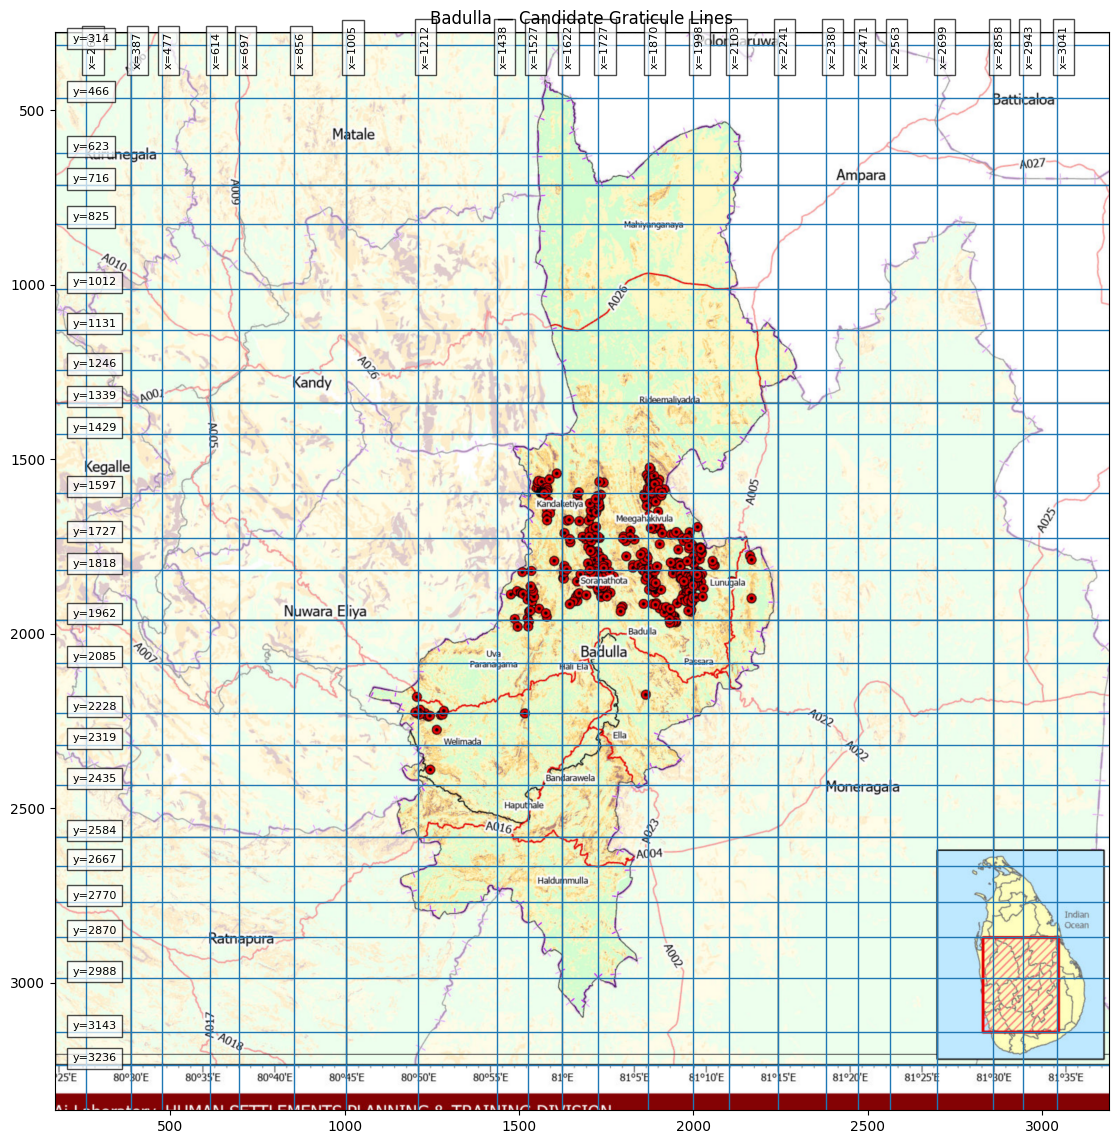

In [13]:
# ============================================================
# VISUAL CHECK OF Badulla GRIDLINE CANDIDATES
# ============================================================

plt.figure(
    figsize=(16, 14)
)

plt.imshow(arr)


# ------------------------------------------------------------
# Vertical longitude candidates
# ------------------------------------------------------------

for x in vertical_px:

    plt.axvline(
        x,
        linewidth=1
    )

    plt.text(
        x + 5,
        Y_MIN + 100,
        f"x={x}",
        rotation=90,
        fontsize=8,
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )


# ------------------------------------------------------------
# Horizontal latitude candidates
# ------------------------------------------------------------

for y in horizontal_px:

    plt.axhline(
        y,
        linewidth=1
    )

    plt.text(
        X_MIN + 50,
        y - 10,
        f"y={y}",
        fontsize=8,
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )


# ------------------------------------------------------------
# Display only detected map frame
# ------------------------------------------------------------

plt.xlim(
    X_MIN,
    X_MAX
)

plt.ylim(
    Y_MAX,
    Y_MIN
)

plt.title(
    "Badulla — Candidate Graticule Lines"
)

plt.show()

In [ ]:
# ============================================================
# BADULLA — PIXEL TO GEOGRAPHIC COORDINATE CALIBRATION
# ============================================================

CALIBRATION = {

    # LONGITUDE

    "lon_a_deg": 80.45,       # 80°30'E
    "lon_a_px": 1005,

    "lon_b_deg": 81.20,       # 81°30'E
    "lon_b_px": 2471,


    # LATITUDE

    "lat_a_deg": 7.40,        # 7°30'N
    "lat_a_px": 466,

    "lat_b_deg": 6.30,    # 6°40'N
    "lat_b_px": 3143
}


# ------------------------------------------------------------
# Calculate pixel scale
# ------------------------------------------------------------

px_per_deg_lon = (
    CALIBRATION["lon_b_px"]
    - CALIBRATION["lon_a_px"]
) / (
    CALIBRATION["lon_b_deg"]
    - CALIBRATION["lon_a_deg"]
)


px_per_deg_lat = (
    CALIBRATION["lat_b_px"]
    - CALIBRATION["lat_a_px"]
) / (
    CALIBRATION["lat_b_deg"]
    - CALIBRATION["lat_a_deg"]
)


# ------------------------------------------------------------
# Convert image pixel -> longitude / latitude
# ------------------------------------------------------------

def px_to_lonlat(x_full, y_full):

    lon = (
        CALIBRATION["lon_a_deg"]
        + (
            x_full
            - CALIBRATION["lon_a_px"]
        ) / px_per_deg_lon
    )

    lat = (
        CALIBRATION["lat_a_deg"]
        + (
            y_full
            - CALIBRATION["lat_a_px"]
        ) / px_per_deg_lat
    )

    return lon, lat


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print(
    "Pixels per degree longitude:",
    px_per_deg_lon
)

print(
    "Pixels per degree latitude :",
    px_per_deg_lat
)

print(
    "Top-left corner:",
    px_to_lonlat(
        X_MIN,
        Y_MIN
    )
)

print(
    "Bottom-right corner:",
    px_to_lonlat(
        X_MAX,
        Y_MAX
    )
)

Pixels per degree longitude: 1954.6666666666667
Pixels per degree latitude : -2433.6363636363626
Top-left corner: (80.02281718963165, 7.477661561449384)
Bottom-right corner: (81.56834924965894, 6.2083675756443775)


In [15]:
# ============================================================
# BADULLA — SAMPLE LANDSLIDE LEGEND DOT COLOUR
# ============================================================

def sample_dot_color_badulla(
    arr,
    x0,
    y0,
    x1,
    y1
):
    region = arr[
        y0:y1,
        x0:x1
    ]

    r = region[:, :, 0].astype(int)
    g = region[:, :, 1].astype(int)
    b = region[:, :, 2].astype(int)

    # Red landslide symbol
    is_red = (
        (r > 150) &
        (g < 100) &
        (b < 100) &
        ((r - g) > 70) &
        ((r - b) > 70)
    )

    ys, xs = np.where(is_red)

    if len(ys) == 0:
        raise ValueError(
            "No red pixels found in Badulla legend crop — "
            "adjust the legend region."
        )

    samples = region[
        ys,
        xs
    ]

    print(
        f"{len(ys)} red pixels found"
    )

    print(
        "Sample colours:",
        samples[:10]
    )

    print(
        "Median RGB:",
        np.median(samples, axis=0)
    )

    return samples, len(ys)

In [16]:
# Landslide dot detection — handles fused/overlapping clusters of dots.
#
# Roads/text vs. dot clusters are told apart with an EROSION test instead
# of aspect-ratio/solidity: shrink each red blob by a couple of pixels.
#   - A thin road or text stroke disappears completely under erosion.
#   - A cluster of overlapping dots still has a solid core left over,
#     no matter how large or irregularly shaped the cluster is.
# This lets large fused clusters through (which the old aspect/solidity/
# max-size filters were wrongly rejecting), while still discarding roads.
#
# Splitting still uses the two-pass median-area calibration: the number of
# points inside a blob = round(area / single_dot_area), found as separated
# peaks of a smoothed distance transform, capped at that expected count.

import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.measure import regionprops
from skimage.morphology import disk, binary_opening, binary_erosion


def _find_valid_blobs(
    arr, x_min, x_max, y_min, y_max,
    r_min, g_max, b_max, red_diff,
    min_area, erosion_radius, min_fill
):
    body = arr[y_min:y_max, x_min:x_max]
    r = body[:, :, 0].astype(np.int16)
    g = body[:, :, 1].astype(np.int16)
    b = body[:, :, 2].astype(np.int16)

    red_mask = (
        (r >= r_min) & (g <= g_max) & (b <= b_max) &
        ((r - g) >= red_diff) & ((r - b) >= red_diff)
    )
    red_clean = binary_opening(red_mask, footprint=disk(1))
    labeled, n = ndimage.label(red_clean, structure=np.ones((3, 3)))

    valid_regions = []
    for region in regionprops(labeled):
        area = region.area
        if area < min_area:
            continue

        minr, minc, maxr, maxc = region.bbox
        h, w = maxr - minr, maxc - minc
        fill_ratio = area / (w * h) if w and h else 0
        if fill_ratio < min_fill:
            continue  # too sparse to be a solid dot/cluster

        # Erosion test: thin roads/text vanish, round dot clusters survive.
        local = labeled[minr:maxr, minc:maxc] == region.label
        eroded = binary_erosion(local, footprint=disk(erosion_radius))
        if eroded.sum() == 0:
            continue  # thin line -> reject

        valid_regions.append(region)

    return red_mask, labeled, valid_regions


def detect_dots(
    arr,
    x_min, x_max, y_min, y_max,

    # Red colour
    r_min=150, g_max=100, b_max=100, red_diff=70,

    # Shape filters -- now just area floor + fill ratio + erosion survival
    min_area=35,
    min_fill=0.45,
    erosion_radius=2,

    # Splitting behaviour
    single_dot_area=None,   # None -> auto-calibrate from median blob area on this map
    split_threshold=1.4,    # a blob must be at least this many x single_dot_area before splitting
    min_distance=7,
    smooth_sigma=1.5
):
    red_mask, labeled, valid_regions = _find_valid_blobs(
        arr, x_min, x_max, y_min, y_max,
        r_min, g_max, b_max, red_diff,
        min_area, erosion_radius, min_fill
    )

    areas = np.array([reg.area for reg in valid_regions])

    if single_dot_area is None:
        # Median is robust to the occasional huge fused cluster skewing it,
        # since most blobs on the map are still isolated single dots.
        single_dot_area = float(np.median(areas))
        print(f"Auto-calibrated single_dot_area = {single_dot_area:.1f} px "
              f"(from {len(areas)} candidate blobs)")

    marker_mask = np.zeros(labeled.shape, dtype=bool)
    points_px = []

    for region in valid_regions:
        minr, minc, maxr, maxc = region.bbox
        area = region.area
        marker_mask[labeled == region.label] = True

        pad = 3
        r0 = max(minr - pad, 0)
        c0 = max(minc - pad, 0)
        r1 = min(maxr + pad, labeled.shape[0])
        c1 = min(maxc + pad, labeled.shape[1])

        local_mask = labeled[r0:r1, c0:c1] == region.label
        local_dist = ndimage.distance_transform_edt(local_mask)
        if smooth_sigma > 0:
            local_dist = ndimage.gaussian_filter(local_dist, sigma=smooth_sigma)

        if area < single_dot_area * split_threshold:
            expected_n = 1
        else:
            expected_n = max(1, round(area / single_dot_area))

        if expected_n == 1:
            cy, cx = np.unravel_index(np.argmax(local_dist), local_dist.shape)
            points_px.append((cx + c0 + x_min, cy + r0 + y_min))
        else:
            coords = peak_local_max(
                local_dist,
                min_distance=min_distance,
                labels=local_mask,
                num_peaks=expected_n,
                exclude_border=False
            )
            if len(coords) == 0:
                cy, cx = region.centroid
                points_px.append((cx + x_min, cy + y_min))
            else:
                for cy, cx in coords:
                    points_px.append((cx + c0 + x_min, cy + r0 + y_min))

    return points_px, red_mask, marker_mask, single_dot_area


In [17]:
import numpy as np


def remove_duplicate_points(points_px, duplicate_radius=10):
    """
    Safety-net merge for any detections that still end up implausibly close
    together (e.g. two adjacent blobs each independently centring on the
    same seam). Nearby points are averaged into one.
    """
    if not points_px:
        return []

    points = np.array(points_px, dtype=float)
    used = np.zeros(len(points), dtype=bool)
    kept = []

    for i in range(len(points)):
        if used[i]:
            continue
        cluster = [points[i]]
        used[i] = True
        for j in range(i + 1, len(points)):
            if used[j]:
                continue
            if np.linalg.norm(points[i] - points[j]) < duplicate_radius:
                cluster.append(points[j])
                used[j] = True
        cluster = np.array(cluster)
        kept.append(tuple(cluster.mean(axis=0)))

    return kept


In [18]:
points_raw, red_mask, marker_mask, SINGLE_DOT_AREA = detect_dots(
    arr,
    X_MIN, X_MAX, Y_MIN, Y_MAX,
    single_dot_area=None,   # auto-calibrate from the map's own dots
    split_threshold=1.6,
    min_distance=8,
    smooth_sigma=1.5
)

print("Raw detected:", len(points_raw))

points_px = remove_duplicate_points(points_raw, duplicate_radius=10)

print("After duplicate removal:", len(points_px))


C:\Users\PCC\AppData\Local\Temp\ipykernel_12268\3720505156.py:36: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  red_clean = binary_opening(red_mask, footprint=disk(1))
C:\Users\PCC\AppData\Local\Temp\ipykernel_12268\3720505156.py:53: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded = binary_erosion(local, footprint=disk(erosion_radius))


Auto-calibrated single_dot_area = 186.0 px (from 201 candidate blobs)
Raw detected: 265
After duplicate removal: 259


In [19]:
def build_geodataframe(points_px, px_to_lonlat_fn, district_name, source_label):
    records = []
    for x, y in points_px:
        lon, lat = px_to_lonlat_fn(x, y)
        records.append({"longitude": lon, "latitude": lat})
    df = pd.DataFrame(records)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
    gdf["label"] = 1
    gdf["source"] = source_label
    gdf["district"] = district_name
    return gdf

gdf = build_geodataframe(points_px, px_to_lonlat, MAP_NAME.capitalize(), f"NBRO_{MAP_NAME}_map_extracted")

out_path = DATA_PROCESSED / f"{MAP_NAME}_landslides_extracted.gpkg"
gdf.to_file(out_path, driver="GPKG")
print(f"Saved {len(gdf)} points to {out_path}")
print("Bounds:", gdf.total_bounds)

Saved 259 points to ..\data\processed\Badulla_landslides_extracted.gpkg
Bounds: [80.54924966  6.53175196 81.04703274  6.96690325]


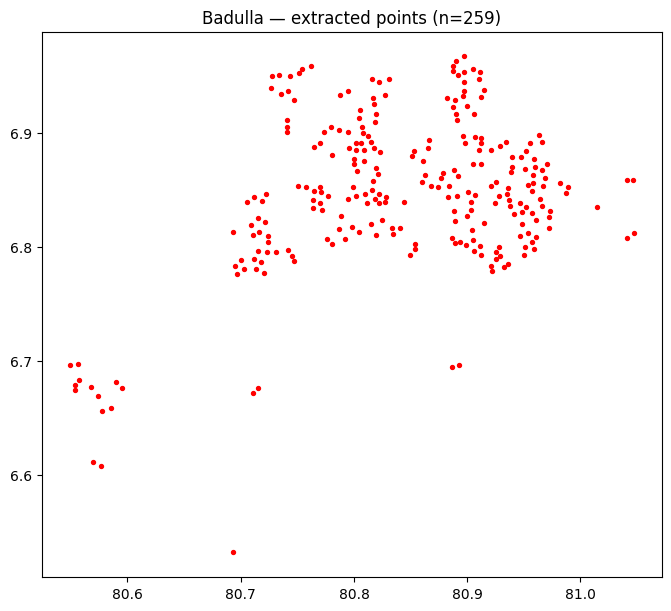

In [20]:
fig, ax = plt.subplots(figsize=(8,8))
gdf.plot(ax=ax, color="red", markersize=8)
ax.set_title(f"{MAP_NAME.capitalize()} — extracted points (n={len(gdf)})")
plt.show()

In [21]:
# ----- CHANGE PER MAP: read the total from the map's own DSD table -----
PRINTED_TOTAL = 368#
# -------------------------------------------------------------------------

match_pct = len(gdf) / PRINTED_TOTAL * 100
print(f"Detected: {len(gdf)} / Printed total: {PRINTED_TOTAL} ({match_pct:.1f}% match)")

Detected: 259 / Printed total: 368 (70.4% match)


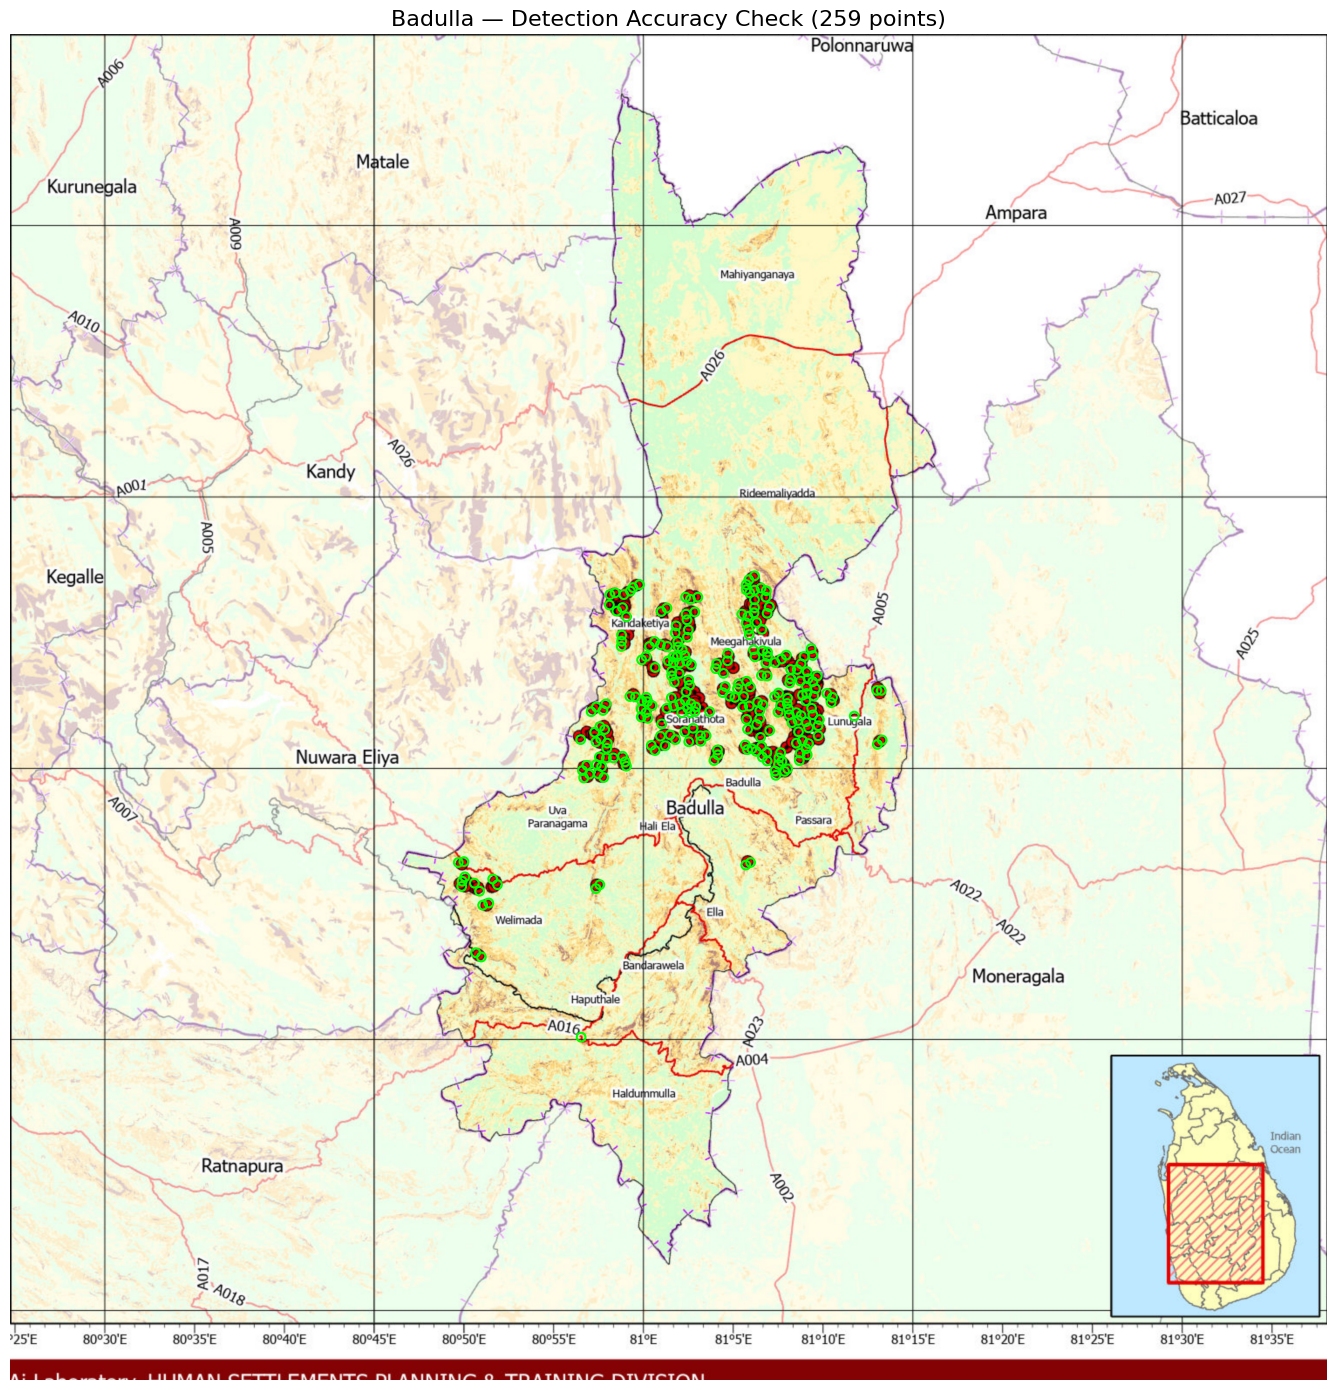

In [22]:
# Visual QA: overlay detected points on original NBRO map
# Circles are drawn in image-pixel (data) coordinates, sized to match
# the actual dot radius calibrated from SINGLE_DOT_AREA, so they scale
# correctly no matter how far you zoom in.

import numpy as np
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(14, 14))

ax.imshow(arr)

# radius (in px) of a single dot, from area = pi * r^2
dot_radius_px = np.sqrt(SINGLE_DOT_AREA / np.pi)

circles = [
    mpatches.Circle((x, y), radius=dot_radius_px * 1.3)  # slight margin so the ring is visible around the dot
    for x, y in points_px
]

ax.add_collection(
    PatchCollection(
        circles,
        facecolor="none",
        edgecolor="lime",
        linewidths=1.5
    )
)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MAX, Y_MIN)  # image Y axis runs downward

ax.set_title(
    f"{MAP_NAME.capitalize()} — Detection Accuracy Check ({len(points_px)} points)",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.show()

In [29]:
import pandas as pd

rows = []
for i, (px, py) in enumerate(points_px, start=1):
    lon, lat = px_to_lonlat(px, py)
    rows.append({
        "id": i,
        "longitude": lon,
        "latitude": lat,
        "area_name": MAP_NAME.capitalize(),
        "pixel_x": px,
        "pixel_y": py
    })

df = pd.DataFrame(rows)
df.to_csv(DATA_PROCESSED /"Badulla_landslide_points.csv", index=False)
print(f"Saved {len(df)} points to Badulla_landslide_points.csv")

Saved 259 points to Badulla_landslide_points.csv


### Part-02 Training table

In [25]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from shapely.geometry import Point

In [30]:
#  load your extracted Badulla landslide CSV

csv_path = DATA_PROCESSED / "Badulla_landslide_points.csv"

assert csv_path.exists(), f"File not found: {csv_path}"

df = pd.read_csv(csv_path)

print(f"Rows loaded: {len(df)}")
print("Columns:", df.columns.tolist())

display(df.head())

Rows loaded: 259
Columns: ['id', 'longitude', 'latitude', 'area_name', 'pixel_x', 'pixel_y']


,id,longitude,latitude,area_name,pixel_x,pixel_y
0,1,80.890484,6.963205,Badulla,1866.0,1529.0
1,2,80.897135,6.966903,Badulla,1879.0,1520.0
2,3,80.754400,6.955809,Badulla,1600.0,1547.0
3,4,80.762074,6.958685,Badulla,1615.0,1540.0
4,5,80.887415,6.958685,Badulla,1860.0,1540.0


In [31]:
#  convert CSV coordinates to GeoDataFrame

Badulla_pts=gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

# Convert to the same UTM CRS used by the Sri Lanka rasters
Badulla_utm = Badulla_pts.to_crs("EPSG:32644")

# Landslide class
Badulla_utm["label"] = 1

print(f"{len(Badulla_utm)} landslide points loaded")
print("CRS:", Badulla_utm.crs)

display(
    Badulla_utm[
        ["id", "longitude", "latitude", "area_name", "label", "geometry"]
    ].head()
)

259 landslide points loaded
CRS: EPSG:32644


,id,longitude,latitude,area_name,label,geometry
0,1,80.890484,6.963205,Badulla,1,POINT (487902.927 769682.72)
1,2,80.897135,6.966903,Badulla,1,POINT (488637.657 770091.375)
2,3,80.754400,6.955809,Badulla,1,POINT (472870.572 768870.722)
3,4,80.762074,6.958685,Badulla,1,POINT (473718.414 769188.261)
4,5,80.887415,6.958685,Badulla,1,POINT (487563.743 769183.131)


In [34]:
# check that extracted points fall inside Kandy

aoi_path = DATA_PROCESSED / "aoi.gpkg"

aoi = gpd.read_file(
    aoi_path,
    layer="districts"
)

# Select Badulla
Badulla_boundary=aoi[
    aoi["adm2_name"].astype(str).str.strip().str.lower() == "badulla"
].copy()

assert len(Badulla_boundary) > 0, "Badulla district not found in AOI"

# IMPORTANT: convert boundary to same CRS as landslide points
Badulla_utm = Badulla_utm.to_crs("EPSG:32644")

# Merge Badulla polygon parts
try:
    Badulla_poly=Badulla_boundary.geometry.union_all()
except AttributeError:
    Badulla_poly = Badulla_boundary.unary_union

# Check points
within_badulla = Badulla_utm.geometry.within(Badulla_poly)

print(
    f"{within_badulla.sum()} / {len(Badulla_utm)} "
    "points fall inside Badulla district"
)

# Keep only valid Badulla points
Badulla_utm = (
    Badulla_utm[within_badulla]
    .copy()
    .reset_index(drop=True)
)

print(f"Final landslide points: {len(Badulla_utm)}")

146 / 146 points fall inside Badulla district
Final landslide points: 146


In [35]:
# generate matching non-landslide points

BUFFER_METERS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Create exclusion area around known landslides
try:
    buffer_union = Badulla_utm.geometry.buffer(BUFFER_METERS).union_all()
except AttributeError:
    buffer_union = Badulla_utm.geometry.buffer(BUFFER_METERS).unary_union

# Valid negative sampling area
valid_area = Badulla_poly.difference(buffer_union)

assert not valid_area.is_empty, "No valid area available for negative sampling"

minx, miny, maxx, maxy = valid_area.bounds

n_needed = len(Badulla_utm)

negatives = []
attempts = 0
max_attempts = max(10000, n_needed * 1000)

while len(negatives) < n_needed and attempts < max_attempts:

    pt = Point(
        rng.uniform(minx, maxx),
        rng.uniform(miny, maxy)
    )

    if valid_area.contains(pt):
        negatives.append(pt)

    attempts += 1


neg_gdf = gpd.GeoDataFrame(
    {
        "label": [0] * len(negatives)
    },
    geometry=negatives,
    crs="EPSG:32644"
)

print(f"Landslide points:     {len(Badulla_utm)}")
print(f"Non-landslide points: {len(neg_gdf)}")
print(f"Sampling attempts:    {attempts}")

Landslide points:     146
Non-landslide points: 146
Sampling attempts:    354


In [36]:
#  combine positive and negative Badulla samples

positive_gdf = Badulla_utm[
    ["geometry", "label"]
].copy()

combined = pd.concat(
    [
        positive_gdf,
        neg_gdf[["geometry", "label"]]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs="EPSG:32644"
)

print("Total Badulla samples:", len(combined))

print("\nClass distribution:")
print(combined["label"].value_counts())

Total Badulla samples: 292

Class distribution:
label
1    146
0    146
Name: count, dtype: int64


In [37]:
# raster sampling helper

def sample_raster_at_points(raster_path, points_gdf, band=1):

    with rasterio.open(raster_path) as src:

        pts = points_gdf.to_crs(src.crs)

        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        values = np.array(
            [v[band - 1] for v in src.sample(coords)],
            dtype="float64"
        )

        # Convert NoData to NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        return values

In [38]:
#sample existing Sri Lanka terrain rasters

raster_map = {
    "slope": "slope.tif",
    "aspect": "aspect.tif",
    "twi": "twi.tif",
    "spi": "spi.tif",
    "dist_to_river": "dist_to_river.tif",
    "dist_to_road": "dist_to_road.tif",
    "elev": "dem_utm.tif",
    "plan_curv": "plan_curvature.tif",
    "profile_curv": "profile_curvature.tif",
}

available_features = []

for name, fname in raster_map.items():

    path = DATA_PROCESSED / fname

    if path.exists():

        combined[name] = sample_raster_at_points(
            path,
            combined
        )

        available_features.append(name)

        print(f"{name}: sampled")

    else:
        print(f"{name}: MISSING — {fname}")

slope: sampled
aspect: sampled
twi: sampled
spi: sampled
dist_to_river: sampled
dist_to_road: sampled
elev: sampled
plan_curv: sampled
profile_curv: sampled


In [39]:
# metadata and cleaning

combined["country"] = "Sri Lanka"
combined["source_dataset"] = "NBRO_Badulla_MapExtraction"
combined["district"] = "Badulla"

# Replace infinite terrain values
combined[available_features] = combined[
    available_features
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing raster values:")
print(combined[available_features].isna().sum())

combined_clean = combined.dropna(
    subset=available_features
).copy()

print(
    f"\nClean Badulla rows: "
    f"{len(combined_clean)} / {len(combined)}"
)

Missing raster values:
slope            0
aspect           0
twi              0
spi              0
dist_to_river    0
dist_to_road     0
elev             0
plan_curv        0
profile_curv     0
dtype: int64

Clean Badulla rows: 292 / 292


In [40]:
# ============================================================
# BADULLA ONLY — FINAL TRAINING TABLE
# No COOLR data
# ============================================================

shared_cols = [
    "geometry",
    "label",
    "country",
    "source_dataset",
    "district",
] + available_features


# Keep only Badulla data
badulla_all = combined_clean[
    shared_cols
].copy()


# Ensure GeoDataFrame
badulla_all = gpd.GeoDataFrame(
    badulla_all,
    geometry="geometry",
    crs="EPSG:32644"
)


print(
    f"Total Badulla samples: "
    f"{len(badulla_all)}"
)

display(
    badulla_all
    .groupby(["source_dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

Total Badulla samples: 292


label,0,1
source_dataset,,
NBRO_Badulla_MapExtraction,146,146


In [41]:
# ============================================================
# SAVE Badulla PARQUET
# ============================================================

parquet_path = (
    DATA_PROCESSED /
    "training_table_badulla.parquet"
)

badulla_all.to_parquet(
    parquet_path,
    index=False
)

print("Saved:", parquet_path)

Saved: ..\data\processed\training_table_badulla.parquet


In [42]:
# ============================================================
# SAVE  CSV
# ============================================================

csv_output = badulla_all.copy()


# UTM coordinates — metres, EPSG:32644
csv_output["x"] = csv_output.geometry.x
csv_output["y"] = csv_output.geometry.y


# Convert to longitude / latitude
wgs84 = csv_output.to_crs(
    "EPSG:4326"
)

csv_output["longitude"] = (
    wgs84.geometry.x
)

csv_output["latitude"] = (
    wgs84.geometry.y
)


# Remove geometry object for CSV
csv_output = pd.DataFrame(
    csv_output.drop(
        columns="geometry"
    )
)


# Save
csv_out_path = (
    DATA_PROCESSED /
    "training_table_badulla.csv"
)

csv_output.to_csv(
    csv_out_path,
    index=False
)       



print("Saved:", csv_out_path)
print("Shape:", csv_output.shape)

display(csv_output.head())

Saved: ..\data\processed\training_table_badulla.csv
Shape: (292, 17)


,label,country,source_dataset,district,slope,aspect,twi,spi,dist_to_river,dist_to_road,elev,plan_curv,profile_curv,x,y,longitude,latitude
0,1,Sri Lanka,NBRO_Badulla_MapExtraction,Badulla,25.890522,243.399002,2.109139,1.941478,1168.933960,247.492859,1272.178711,-0.001869,-2.471315e-04,487902.927429,769682.719745,80.890484,6.963205
1,1,Sri Lanka,NBRO_Badulla_MapExtraction,Badulla,15.092732,312.231384,1.310502,0.269685,1442.792480,214.883972,1285.317017,0.009251,2.138018e-03,488637.657264,770091.374544,80.897135,6.966903
2,1,Sri Lanka,NBRO_Badulla_MapExtraction,Badulla,15.145274,215.546783,2.000007,0.541337,849.056763,0.000000,1115.954346,0.001958,-2.246619e-03,487563.743385,769183.130623,80.887415,6.958685
3,1,Sri Lanka,NBRO_Badulla_MapExtraction,Badulla,10.074154,174.360870,2.421021,0.355324,681.599792,61.395424,1112.796509,0.008138,-4.189744e-04,489485.056835,768819.313313,80.904809,6.955398
4,1,Sri Lanka,NBRO_Badulla_MapExtraction,Badulla,0.000960,82.744698,21.278458,0.489048,43.413120,264.071686,1066.781860,-0.006125,-7.080461e-08,488637.331146,768592.368686,80.897135,6.953343
